# Grocery store closures and replacement openings in Chicago

**Emmanuel Amissah Sampson · Study period 2021–2025**

This notebook documents six verified business events at five premises and places them in the wider SNAP retailer record. The authorization history is not a census of physical store openings and closures.

Publication record: Published · 17 November 2026 · v1.0.0. [Website](https://emmanuelsampson-prog.github.io/grocery-access-chicago/) · [Repository](https://github.com/emmanuelsampson-prog/grocery-access-chicago). All maps and charts are generated with Matplotlib.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import geopandas as gpd
from IPython.display import display, Image, Markdown
pd.set_option('display.max_columns', 20)
DATA = ROOT / 'data/processed'
FIG = ROOT / 'outputs/figures'


## 1. Data provenance
Public inputs retain source URLs, retrieval times and SHA-256 checksums. The national USDA file is current through 31 December 2025. ACS estimates cover 2017–2021 and provide pre-event context.

In [2]:
manifest = pd.DataFrame(json.loads((ROOT/'data/source_manifest.json').read_text()))
display(manifest[['id','description','bytes','sha256']])

,id,description,bytes,sha256
0,snap_history,USDA historical SNAP authorizations as of 31 D...,24036753,872a6f814a63514a1f1b0c4517a90309a9fbb01d97d6e4...
1,tracts_2020,City of Chicago Census 2020 tract polygons; Ce...,3797769,b527b17ef820d8a20c03bad9da91f0b609826455c0f47d...
2,community_areas_table,City of Chicago community areas (underlying sp...,2069583,e6cd62bdca991d66468e2e389ef6749cd81773facc7ce1...
3,food_inspections,Chicago food inspections 2021–2025: grocery fa...,3521171,e787c4af553c0401668f8cdb626da049ec270597acd519...
4,osm_2023,OpenStreetMap Illinois snapshot 1 January 2023...,243949068,eb62bd3e335259cedfa1ca98c08bfbbbcbc59dc6e3f09d...
5,acs2021_B01003,2017–2021 ACS five-year estimates and margins ...,40065,3e18de634009923eb950ec95c19781063f54cb9f41b7c1...
6,acs2021_B08201,2017–2021 ACS five-year estimates and margins ...,287170,392911058e78d4eb85d5aa9c7cdc5faa1e03f5741103d7...
7,acs2021_B17001,2017–2021 ACS five-year estimates and margins ...,523588,2a6ce9807e253ab007eb4e5d2f77a3168bccc2557864db...
8,acs2021_B19013,2017–2021 ACS five-year estimates and margins ...,44115,1a1db2fcdf587d1ac8ba3c521849ef4621a4d33e3a75a7...


## 2. Verified business events
Closure dates are last open days. Save A Lot occupies the same premises as the closed Whole Foods; this is a replacement opening, not a second new location.

,label,event_type,event_date,address,source_url
0,"Whole Foods, Englewood",closure,2022-11-13,832 W 63rd St,https://www.wbez.org/culture-the-arts/2022/11/...
1,"Walmart, Chatham",closure,2023-04-16,8431 S Stewart Ave,https://corporate.walmart.com/news/2023/04/11/...
2,"Walmart, Kenwood",closure,2023-04-16,4720 S Cottage Grove Ave,https://corporate.walmart.com/news/2023/04/11/...
3,"Walmart, Lakeview",closure,2023-04-16,2844 N Broadway St,https://corporate.walmart.com/news/2023/04/11/...
4,"Walmart, Little Village",closure,2023-04-16,2551 W Cermak Rd,https://corporate.walmart.com/news/2023/04/11/...
5,"Save A Lot, Englewood",opening,2023-05-11,832 W 63rd St,https://chicago.suntimes.com/2023/5/11/2372007...


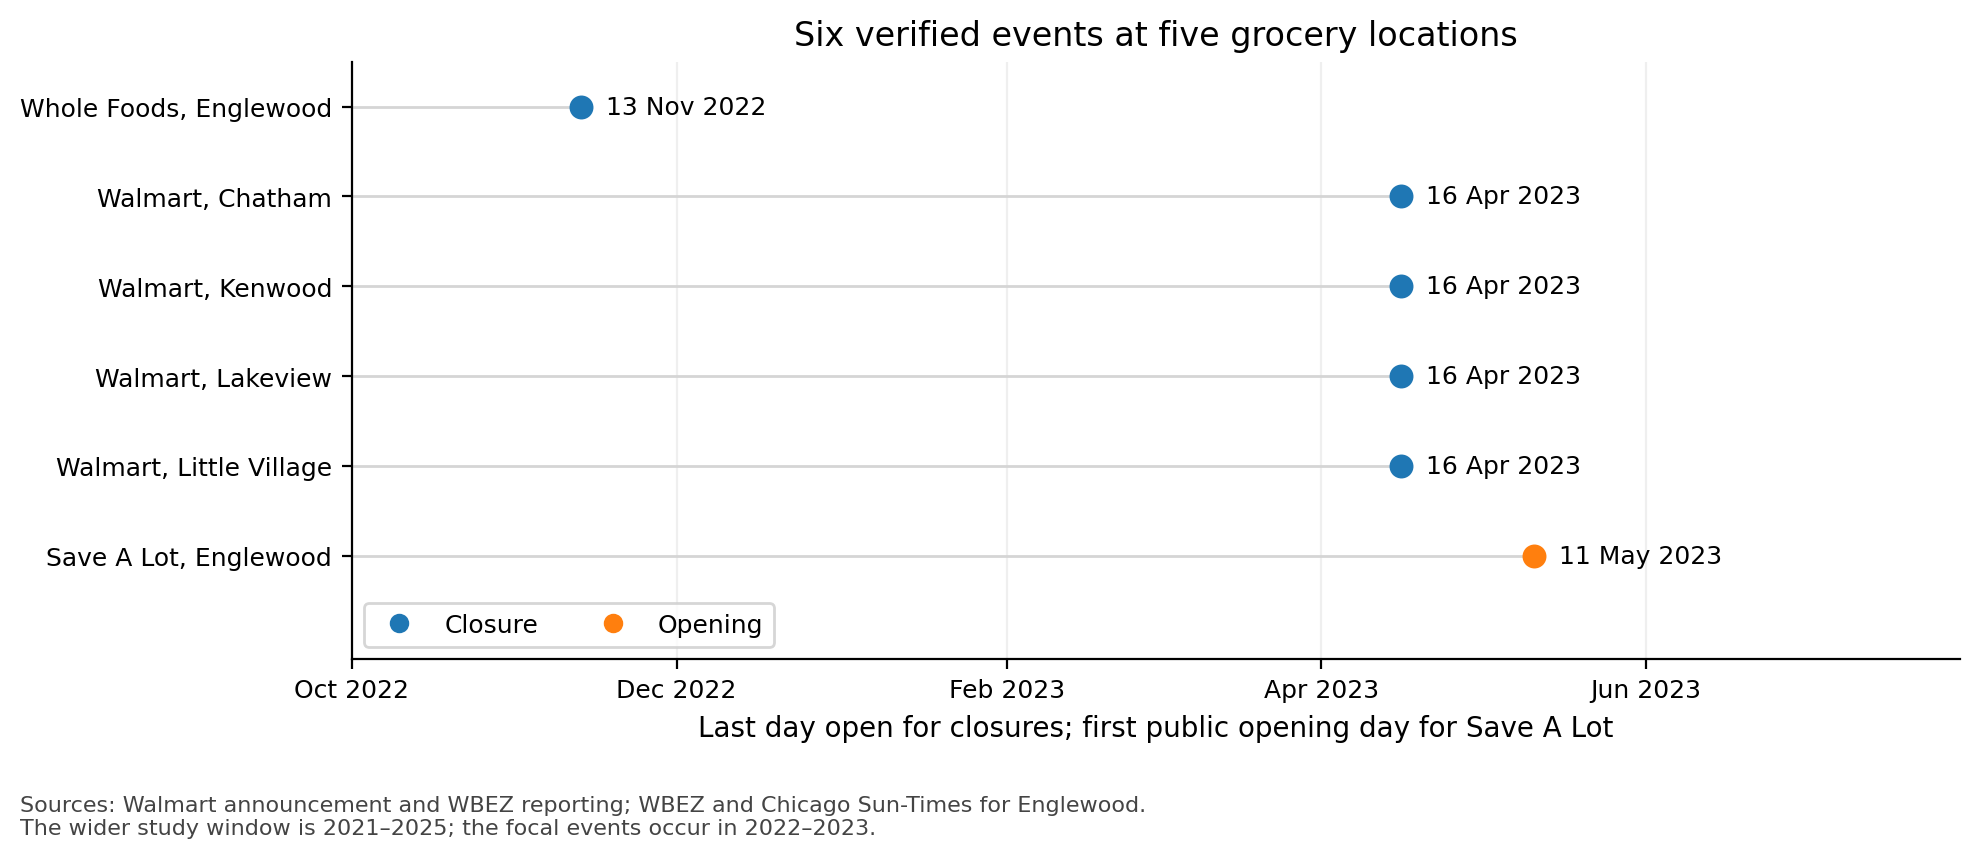

In [3]:
events = pd.read_csv(DATA/'verified_events.csv', dtype={'record_id':str})
display(events[['label','event_type','event_date','address','source_url']])
display(Image(filename=str(FIG/'02_event_timeline.png')))

## 3. Administrative dates need review
SNAP authorization can precede opening or outlast closure. Inspection dates likewise do not establish the exact last operating day. The focal analysis uses reviewed physical dates.

,label,event_date,snap_start,snap_end,administrative_date_gap_days,review_note
0,"Whole Foods, Englewood",2022-11-13,2016-09-19,2023-02-16,95,Common City geocode used for both brands; orig...
1,"Walmart, Chatham",2023-04-16,2011-12-26,2023-04-19,3,City lists 8331 S Stewart Ave; retailer and US...
2,"Walmart, Kenwood",2023-04-16,2014-09-17,2023-04-19,3,Company/store identifier and address corrobora...
3,"Walmart, Lakeview",2023-04-16,2013-01-07,2023-04-19,3,Company/store identifier and address corrobora...
4,"Walmart, Little Village",2023-04-16,2013-01-08,2023-04-19,3,Company/store identifier and address corrobora...
5,"Save A Lot, Englewood",2023-05-11,2023-01-04,NaN,127,Common City geocode used for both brands; orig...


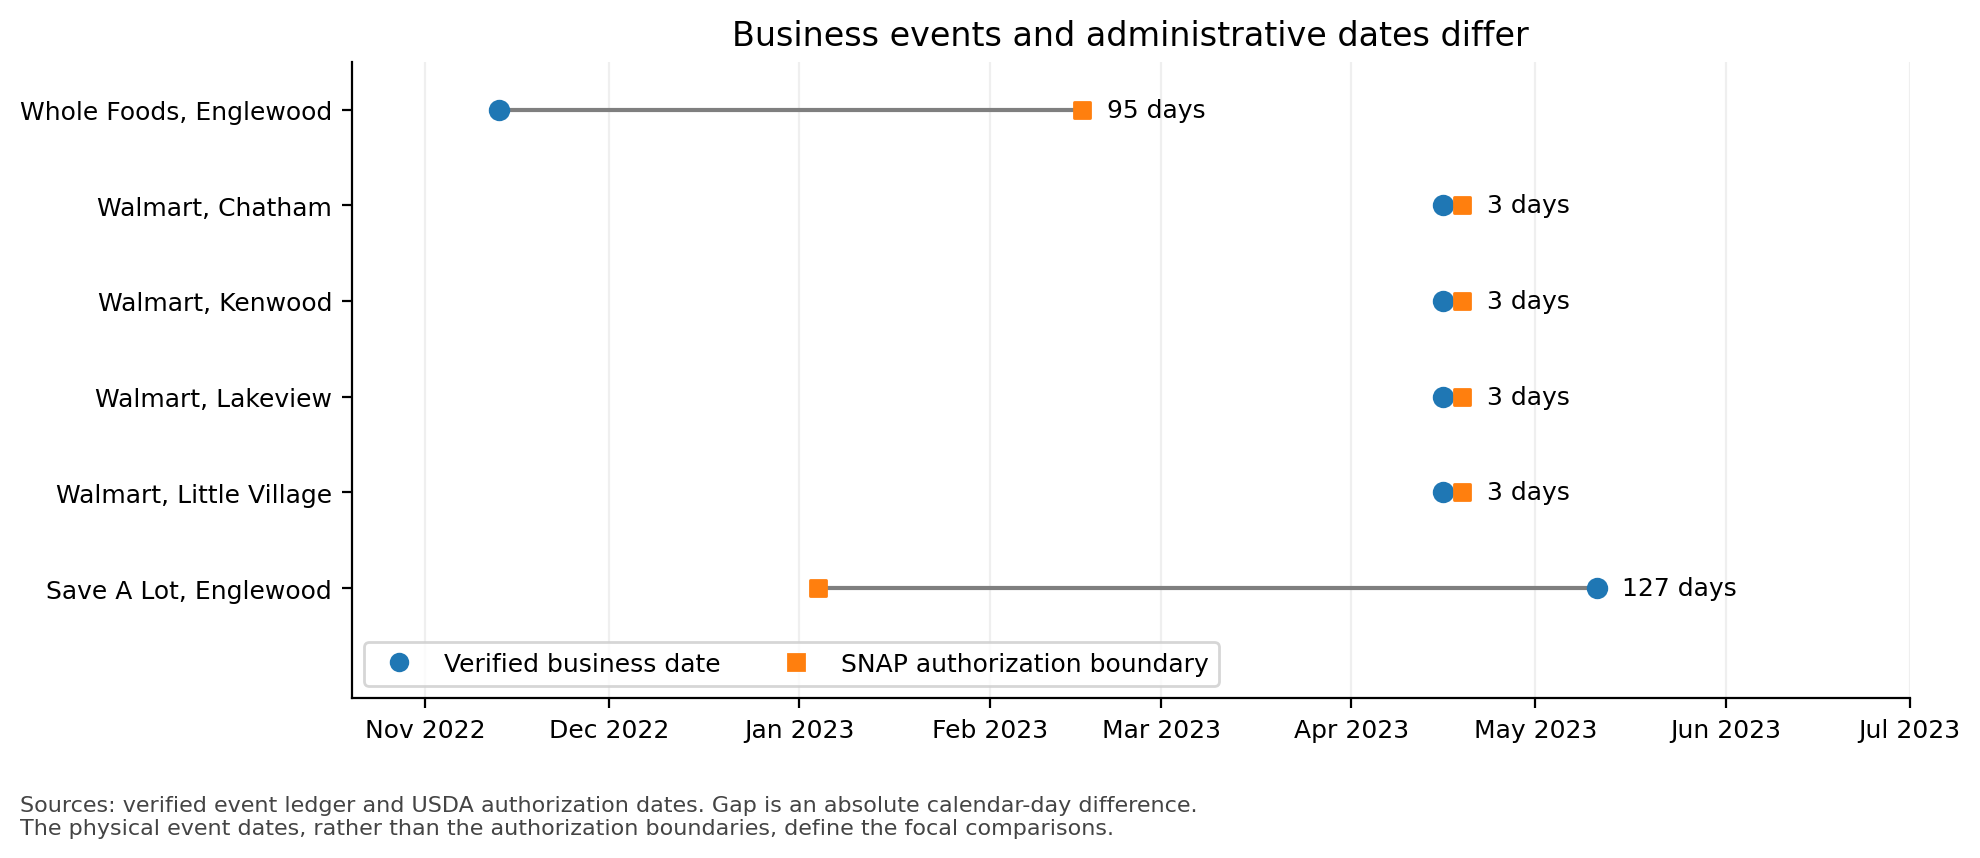

In [4]:
display(events[['label','event_date','snap_start','snap_end','administrative_date_gap_days','review_note']])
display(Image(filename=str(FIG/'04_date_audit.png')))

## 4. Five years of authorization history
The counts below use month-end eligibility and unique standardized address keys. They describe the SNAP program footprint, including broad retailer types, and must not be relabeled as verified store counts.

,first,last,snapshots
scope,,,
all_snap,1848,1807,60
larger_grocery,294,285,60


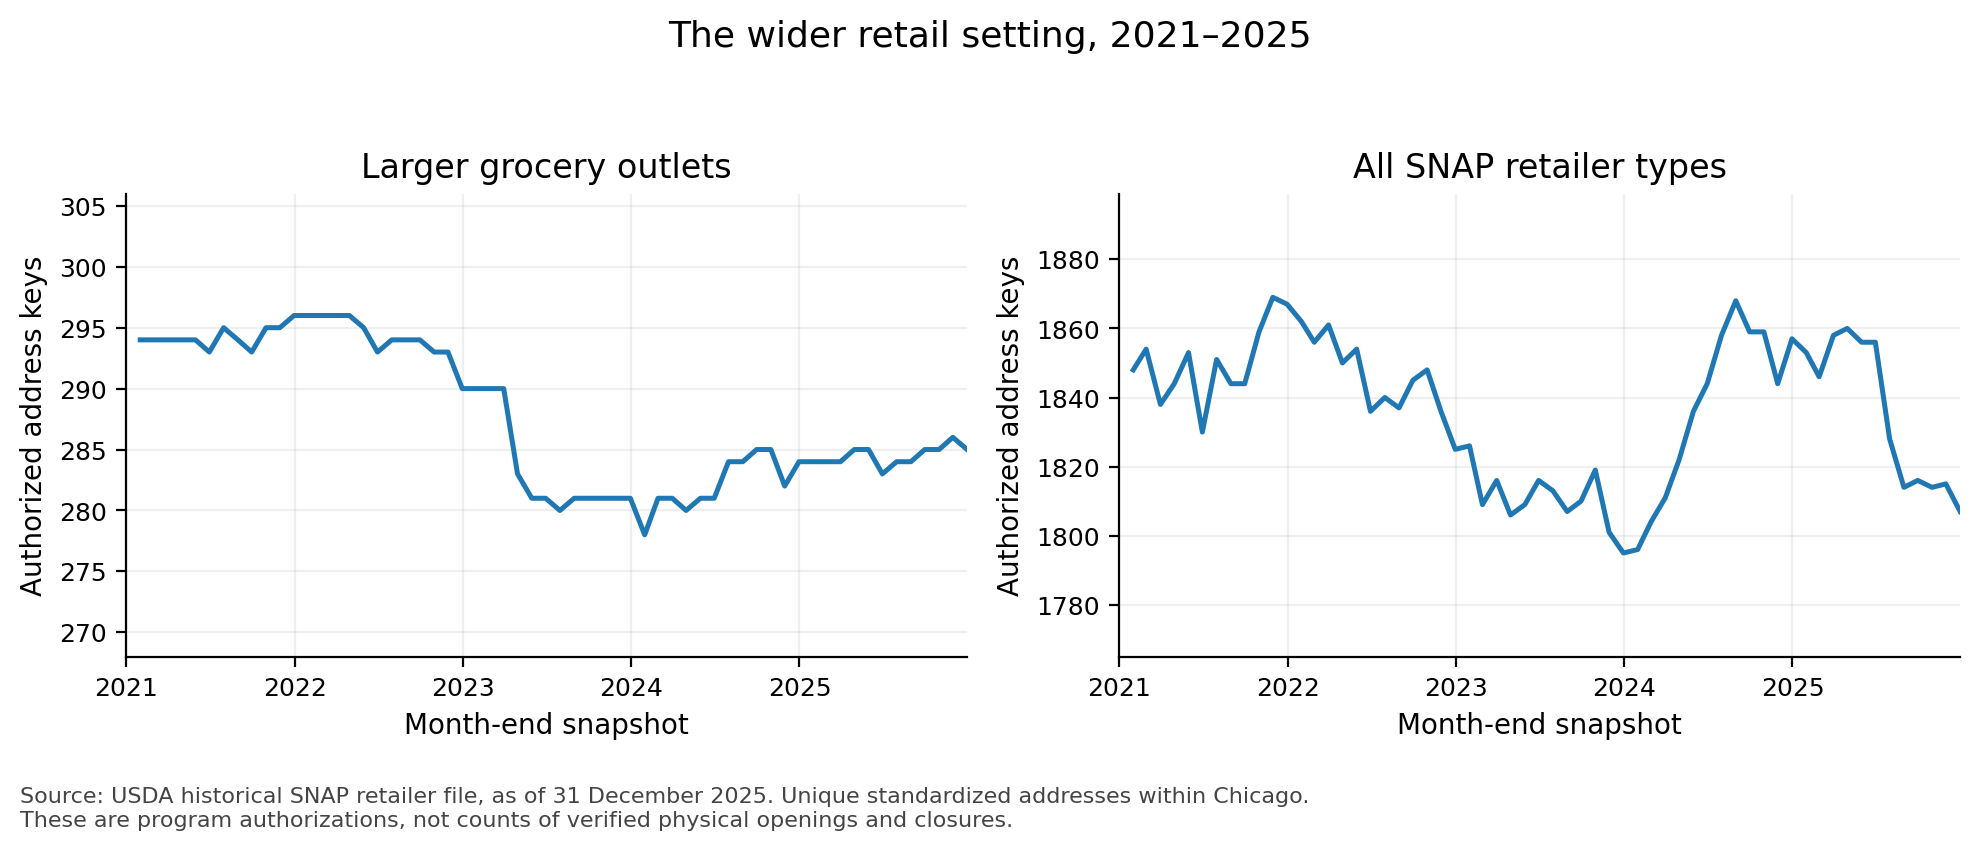

In [5]:
history = pd.read_csv(DATA/'monthly_authorized_inventory.csv')
display(history.groupby('scope').agg(first=('unique_address_keys','first'), last=('unique_address_keys','last'), snapshots=('date','count')))
display(Image(filename=str(FIG/'03_inventory_history.png')))

## 5. Tract context and coordinates
All distance calculations use EPSG:26916, NAD83 / UTM zone 16N, metres. Tract polygons shade neighborhood context; one interior origin summarizes each tract. Population weights do not measure affected shoppers.

tracts                                                                  789
populated_tracts                                                        786
unmatched_acs_tracts                                                     []
regional_authorization_records                                         5156
projection                        EPSG:26916 — NAD83 / UTM zone 16N, metres
dtype: object

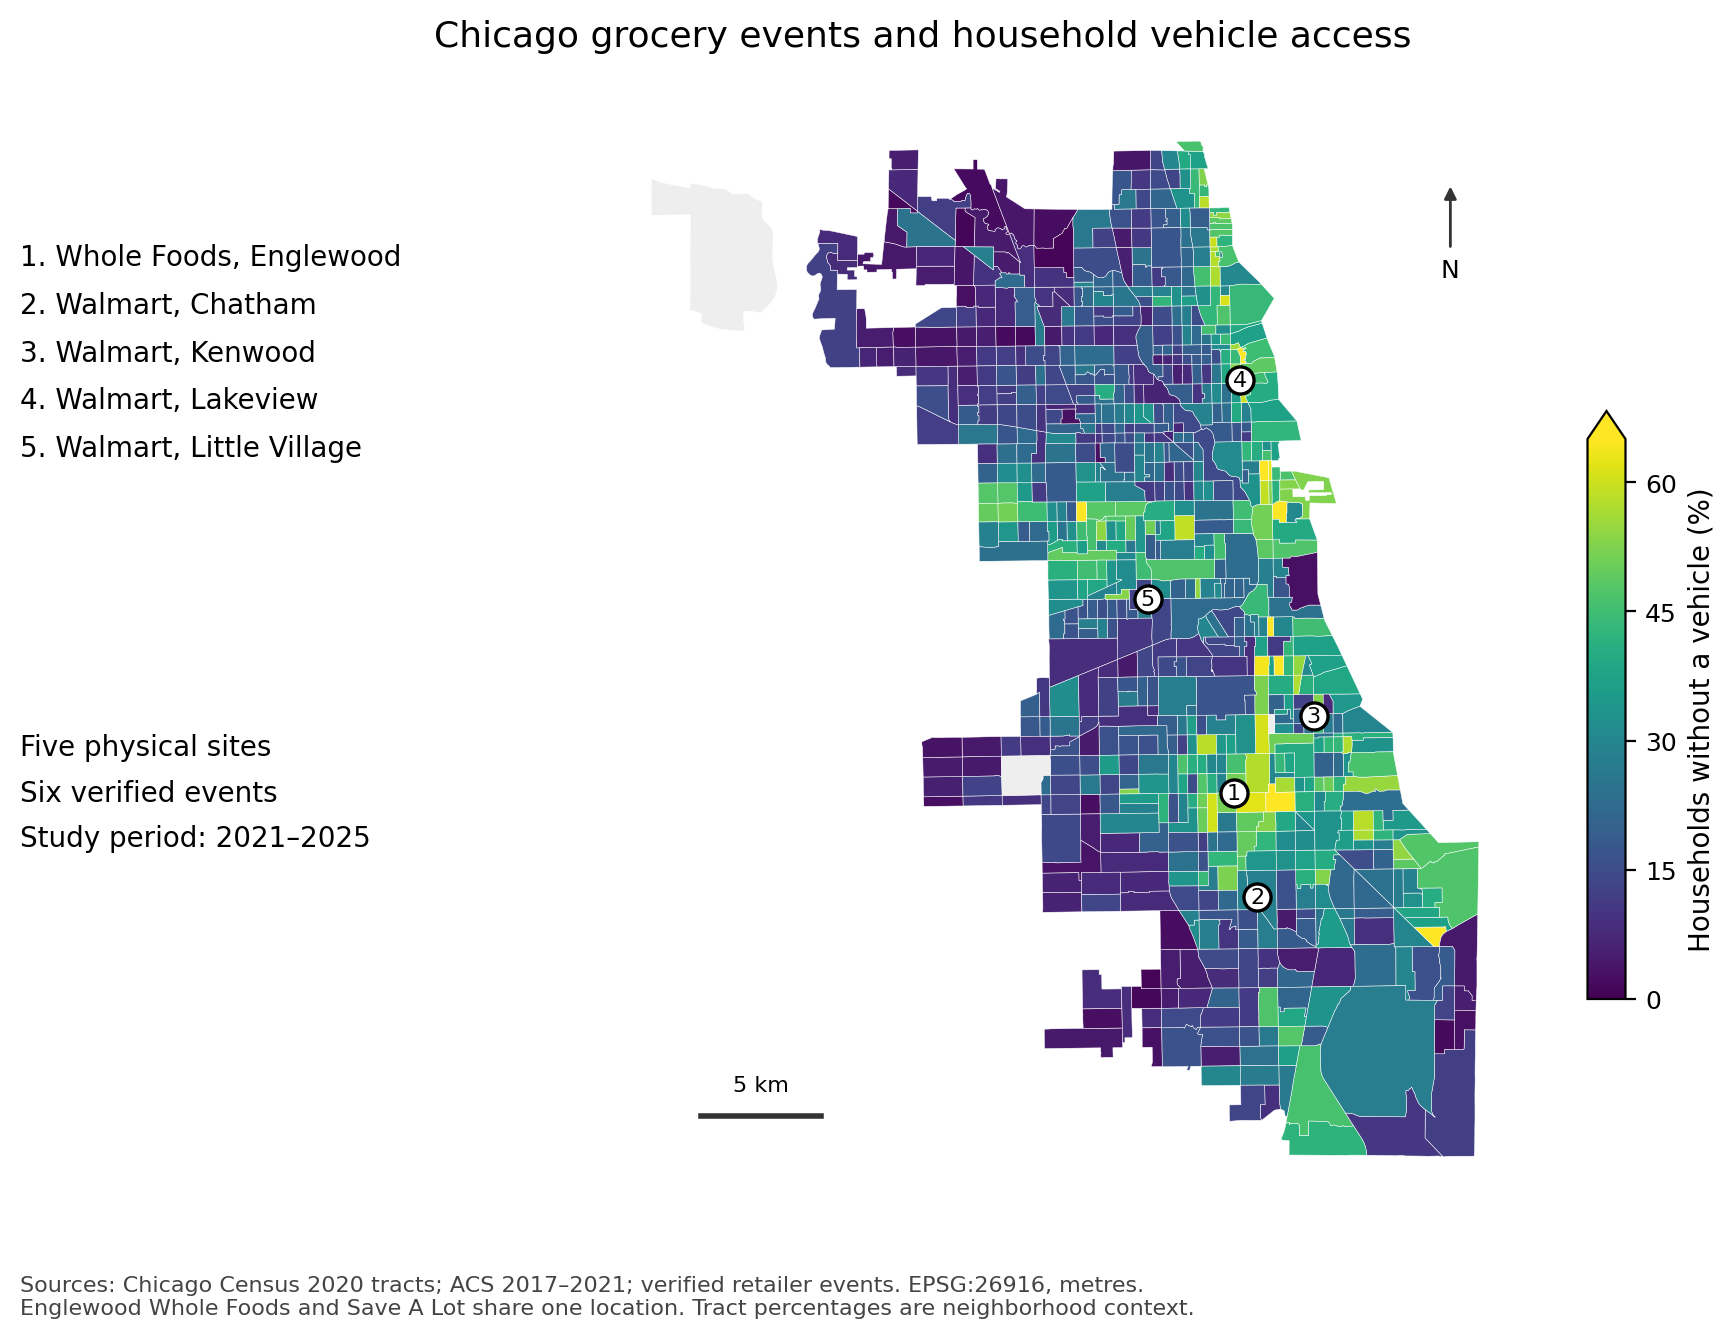

In [6]:
audit = json.loads((DATA/'data_audit.json').read_text())
display(pd.Series({k:audit[k] for k in ['tracts','populated_tracts','unmatched_acs_tracts','regional_authorization_records','projection']}))
display(Image(filename=str(FIG/'01_study_map.png')))

## Interpretation
The executed record establishes dated closures and one replacement opening, quantifies the wider authorization footprint, and exposes date and coordinate discrepancies. It does not establish observed shopping journeys. Continue with notebook 02 for the modeled access comparisons and notebook 03 for the mobility input audit.